In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [2]:
import os
import shutil
import pandas as pd

Name_data_set = "internet_usage"
Surce_path    = r"../data/internet_usage.csv"

if not os.path.exists(Name_data_set):
    if os.path.exists(Surce_path):
        print("Copying dataset to project directory...")
        shutil.copy(Surce_path , Name_data_set )
        print("Dataset successfully copied! ")
    else: 
        print(" Error: Dataset file not found at the source path.")
else: 
    print("Dataset already exists in project directory. Ready to use! ")


Copying dataset to project directory...
Dataset successfully copied! 


In [3]:
df = pd.read_csv("internet_usage")
df.head(5)

,Country Name,Country Code,2000,2001,2002,2003,2004,2005,2006,2007,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Afghanistan,AFG,..,0.00472257,0.0045614,0.0878913,0.105809,1.22415,2.10712,1.9,...,7,8.26,11,13.5,16.8,17.6,18.4,..,..,..
1,Albania,ALB,0.114097,0.325798,0.390081,0.9719,2.42039,6.04389,9.60999,15.0361,...,54.3,56.9,59.6,62.4,65.4,68.5504,72.2377,79.3237,82.6137,83.1356
2,Algeria,DZA,0.491706,0.646114,1.59164,2.19536,4.63448,5.84394,7.37598,9.45119,...,29.5,38.2,42.9455,47.6911,49.0385,58.9776,60.6534,66.2356,71.2432,..
3,American Samoa,ASM,..,..,..,..,..,..,..,..,...,..,..,..,..,..,..,..,..,..,..
4,Andorra,AND,10.5388,..,11.2605,13.5464,26.838,37.6058,48.9368,70.87,...,86.1,87.9,89.7,91.5675,..,90.7187,93.2056,93.8975,94.4855,..


In [4]:
df.tail()

,Country Name,Country Code,2000,2001,2002,2003,2004,2005,2006,2007,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
212,Virgin Islands (U.S.),VIR,13.8151,18.3758,27.4944,27.4291,27.377,27.3443,27.3326,27.3393,...,50.07,54.8391,59.6083,64.3775,..,..,..,..,..,..
213,West Bank and Gaza,PSE,1.11131,1.83685,3.10009,4.13062,4.4009,16.005,18.41,21.176,...,53.6652,56.7,59.9,63.3,64.4,70.6226,76.01,81.83,88.6469,86.6377
214,"Yemen, Rep.",YEM,0.0825004,0.0908025,0.518796,0.604734,0.881223,1.0486,1.24782,5.01,...,22.55,24.0854,24.5792,26.7184,..,..,13.8152,14.8881,17.6948,..
215,Zambia,ZMB,0.191072,0.23313,0.477751,0.980483,1.1,1.3,1.6,1.9,...,6.5,8.8,10.3,12.2,14.3,18.7,24.4992,26.9505,31.2342,..
216,Zimbabwe,ZWE,0.401434,0.799846,1.1,1.8,2.1,2.4,2.4,3,...,16.3647,22.7428,23.12,24.4,25,26.5883,29.2986,32.4616,32.5615,..


In [5]:
df.describe()

,Country Name,Country Code,2000,2001,2002,2003,2004,2005,2006,2007,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
count,217,217,217,217,217,217,217,217,217,217,...,217,217,217,217,217,217,217,217,217,217
unique,217,217,197,200,202,196,198,199,199,197,...,194,196,199,203,175,183,191,185,178,58
top,Afghanistan,AFG,..,..,..,..,..,..,..,..,...,..,..,..,..,..,..,..,..,..,..
freq,1,1,21,18,15,21,18,17,18,13,...,16,17,14,11,41,31,25,27,34,158


In [6]:
china = df[df['Country Name'] == 'China']
china

,Country Name,Country Code,2000,2001,2002,2003,2004,2005,2006,2007,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
41,China,CHN,1.77591,2.63965,4.5957,6.2,7.3,8.52326,10.5232,16,...,47.9,50.3,53.2,54.3,59.2,64.0809,70.0528,73.0532,75.6113,77.4827


In [7]:
x_data = china.columns[2:].astype(int).to_numpy()

y_data = china.iloc[0, 2:].to_numpy(dtype=float)

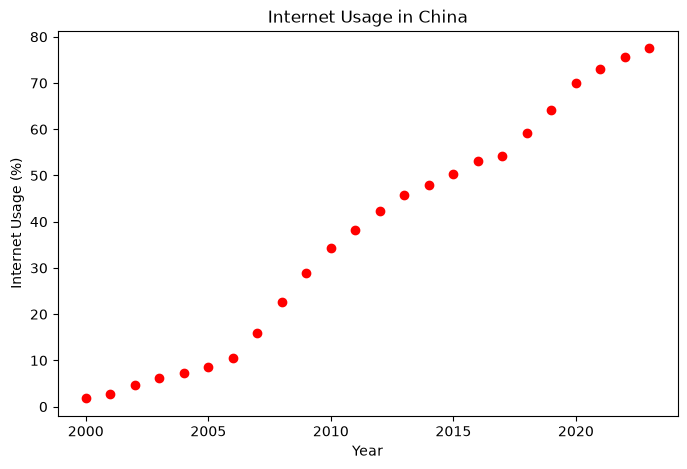

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(x_data, y_data, 'ro')
plt.xlabel('Year')
plt.ylabel('Internet Usage (%)')
plt.title('Internet Usage in China')
plt.show()

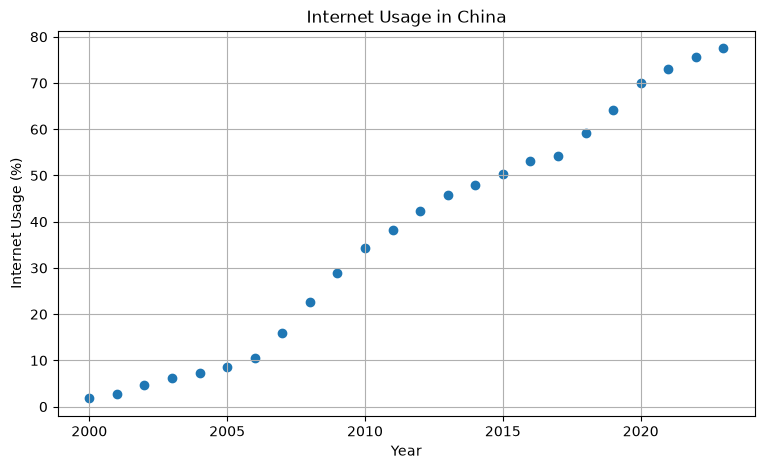

In [9]:
plt.figure(figsize=(9, 5))
plt.scatter(x_data, y_data)
plt.xlabel('Year')
plt.ylabel('Internet Usage (%)')
plt.title('Internet Usage in China')
plt.grid()
plt.show()

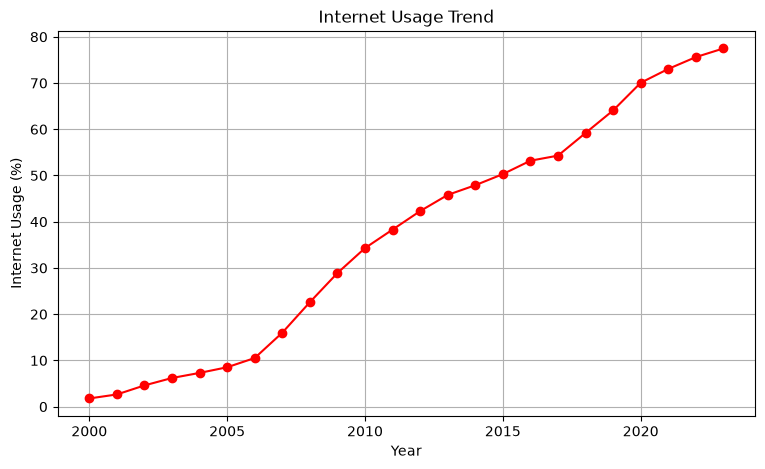

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(x_data, y_data, 'r-o')
plt.xlabel('Year')
plt.ylabel('Internet Usage (%)')
plt.title('Internet Usage Trend')
plt.grid()
plt.show()

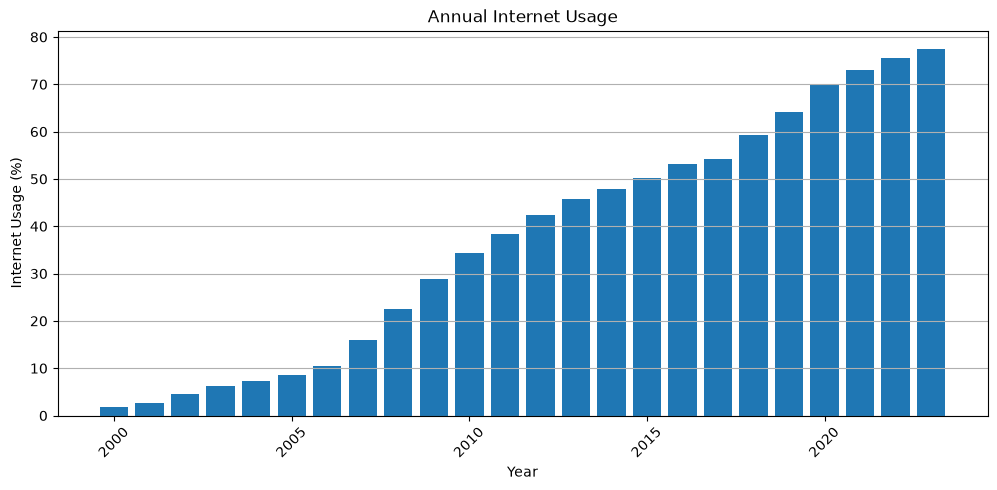

In [11]:
plt.figure(figsize=(12, 5))
plt.bar(x_data, y_data)
plt.xlabel('Year')
plt.ylabel('Internet Usage (%)')
plt.title('Annual Internet Usage')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

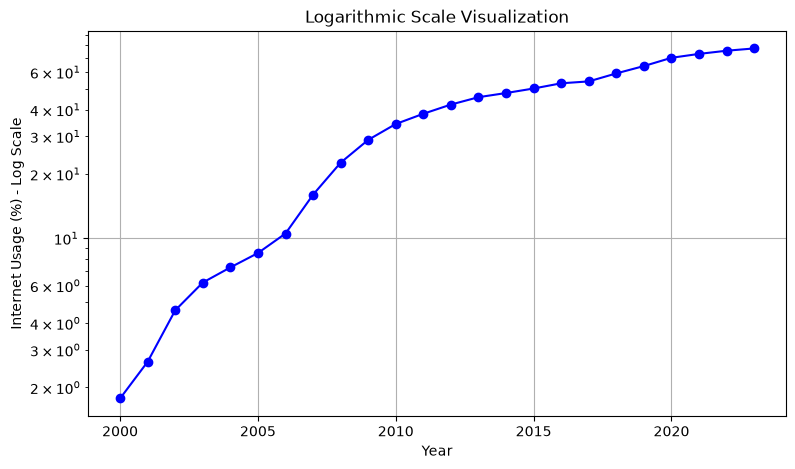

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(x_data, y_data, 'bo-')
plt.yscale('log')
plt.xlabel('Year')
plt.ylabel('Internet Usage (%) - Log Scale')
plt.title('Logarithmic Scale Visualization')
plt.grid()
plt.show()

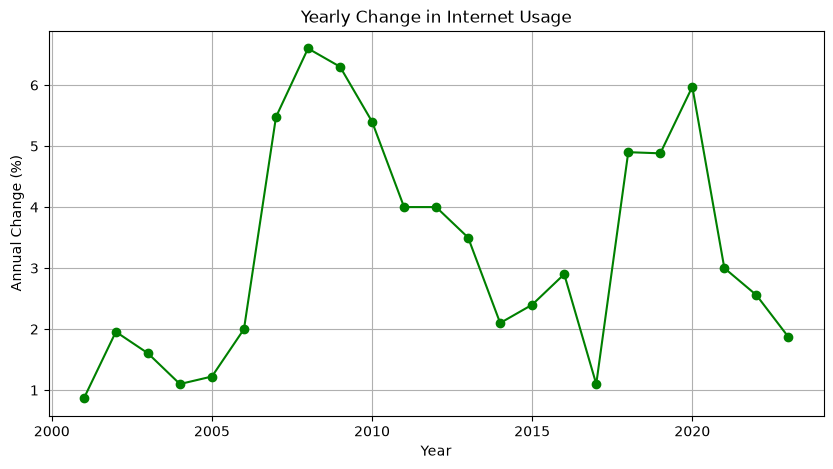

In [13]:
growth = np.diff(y_data)

plt.figure(figsize=(10, 5))
plt.plot(x_data[1:], growth, 'g-o')
plt.xlabel('Year')
plt.ylabel('Annual Change (%)')
plt.title('Yearly Change in Internet Usage')
plt.grid()
plt.show()

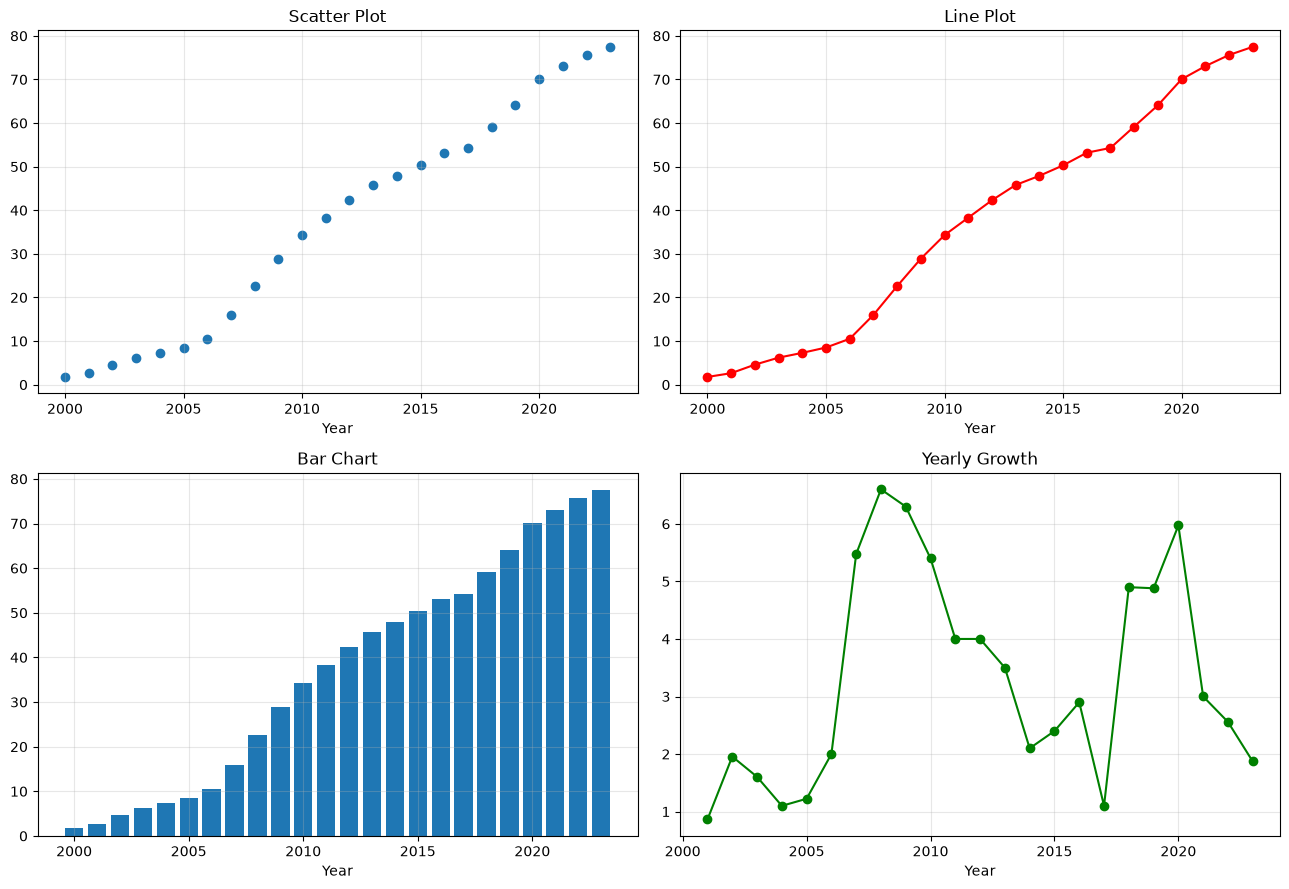

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].scatter(x_data, y_data)
axes[0, 0].set_title('Scatter Plot')

axes[0, 1].plot(x_data, y_data, 'r-o')
axes[0, 1].set_title('Line Plot')

axes[1, 0].bar(x_data, y_data)
axes[1, 0].set_title('Bar Chart')

axes[1, 1].plot(x_data[1:], np.diff(y_data), 'g-o')
axes[1, 1].set_title('Yearly Growth')

for ax in axes.flat:
    ax.set_xlabel('Year')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# Exponential Function
def exponential(x, a, b, c):
    return a * np.exp(b * (x - 2000)) + c


# Logarithmic Function
def logarithmic(x, a, b):
    return a * np.log(x - 1999) + b


# Sigmoid Function
def sigmoid(x, L, k, x0):
    return L / (1 + np.exp(-k * (x - x0)))

In [16]:
# Exponential Model
popt_exp, _ = curve_fit(
    exponential,
    x_data,
    y_data,
    p0=[2, 0.1, 0],
    maxfev=20000
)


# Logarithmic Model
popt_log, _ = curve_fit(
    logarithmic,
    x_data,
    y_data,
    p0=[15, 0]
)


# Sigmoid Model
popt_sig, _ = curve_fit(
    sigmoid,
    x_data,
    y_data,
    p0=[100, 0.2, 2012],
    maxfev=20000
)

In [17]:
y_exp = exponential(x_data, *popt_exp)

y_log = logarithmic(x_data, *popt_log)

y_sig = sigmoid(x_data, *popt_sig)

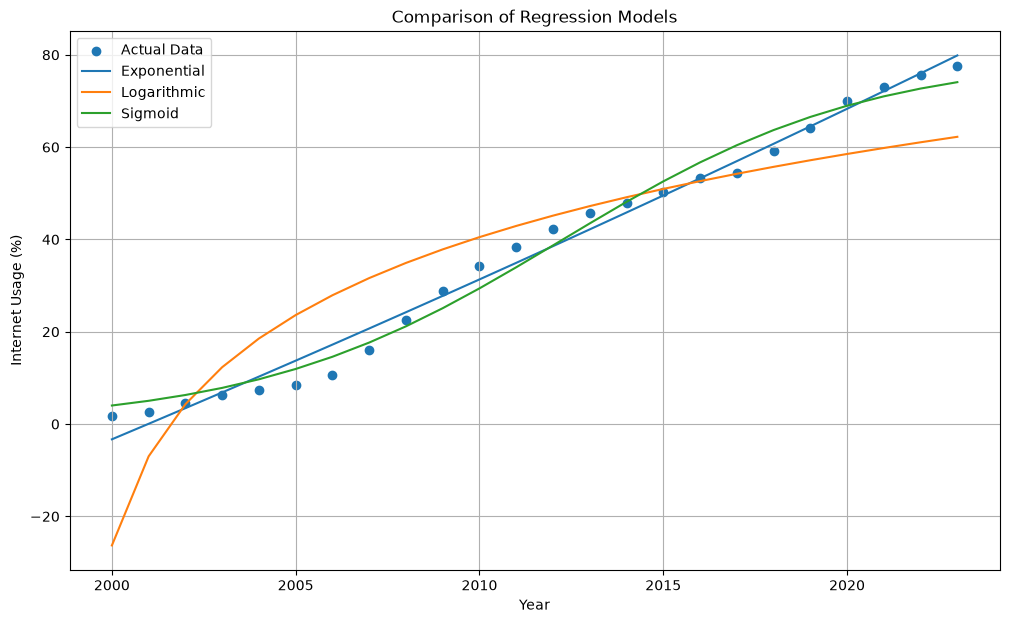

In [18]:
plt.figure(figsize=(12, 7))

plt.scatter(x_data, y_data, label='Actual Data')

plt.plot(x_data, y_exp, label='Exponential')
plt.plot(x_data, y_log, label='Logarithmic')
plt.plot(x_data, y_sig, label='Sigmoid')

plt.xlabel('Year')
plt.ylabel('Internet Usage (%)')
plt.title('Comparison of Regression Models')

plt.legend()
plt.grid()
plt.show()

In [19]:
models = {
    'Exponential': y_exp,
    'Logarithmic': y_log,
    'Sigmoid': y_sig
}

for name, predictions in models.items():

    r2 = r2_score(y_data, predictions)

    mae = mean_absolute_error(y_data, predictions)

    rmse = np.sqrt(mean_squared_error(y_data, predictions))

    print(f'{name}:')
    print(f'R2: {r2:.4f}')
    print(f'MAE: {mae:.4f}')
    print(f'RMSE: {rmse:.4f}')
    print('-' * 30)

Exponential:
R2: 0.9861
MAE: 2.4342
RMSE: 2.9768
------------------------------
Logarithmic:
R2: 0.8074
MAE: 8.6389
RMSE: 11.0605
------------------------------
Sigmoid:
R2: 0.9845
MAE: 2.8505
RMSE: 3.1426
------------------------------


In [20]:
print("Exponential Parameters:", popt_exp)
print("Logarithmic Parameters:", popt_log)
print("Sigmoid Parameters:", popt_sig)

Exponential Parameters: [ 5.18506863e+02  6.46808674e-03 -5.21816498e+02]
Logarithmic Parameters: [ 27.8574753  -26.30106357]
Sigmoid Parameters: [7.96726831e+01 2.39915738e-01 2.01223726e+03]
